In [1]:
import pandas as pd
import numpy as np
import json
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px


In [ ]:
from pathlib import Path

def carpeta_proyecto(nombre, marca):
    """Localiza los CSV en Jupyter, Visual Studio Code y Colab."""
    from pathlib import Path
    import json

    saltar = {
        ".config", "sample_data", "drive", ".git", "__pycache__",
        "node_modules", ".ipynb_checkpoints", "site-packages",
    }

    def directorio_notebook():
        try:
            return Path(__vsc_ipynb_file__).resolve().parent
        except NameError:
            pass
        try:
            from urllib.request import urlopen
            try:
                from ipykernel.connect import get_connection_file
            except ImportError:
                from ipykernel import get_connection_file
            conexion = Path(get_connection_file())
            kernel_id = conexion.name.replace("kernel-", "").replace(".json", "")
            servidores = list(conexion.parent.glob("jpserver-*.json"))[:3]
            for servidor in servidores:
                try:
                    info = json.loads(servidor.read_text(encoding="utf-8"))
                except (OSError, json.JSONDecodeError):
                    continue
                url = str(info.get("url", "")).rstrip("/")
                raiz = info.get("root_dir")
                if not url or not raiz:
                    continue
                api = url + "/api/sessions"
                token = info.get("token") or ""
                if token:
                    api += "?token=" + token
                try:
                    with urlopen(api, timeout=0.8) as respuesta:
                        sesiones = json.loads(respuesta.read().decode())
                except Exception:
                    continue
                for sesion in sesiones:
                    kid = (sesion.get("kernel") or {}).get("id")
                    if kid != kernel_id:
                        continue
                    cuaderno = sesion.get("notebook") or {}
                    relativo = cuaderno.get("path") or sesion.get("path")
                    if relativo:
                        return (Path(raiz) / relativo).resolve().parent
        except Exception:
            pass
        return None

    bases = []
    notebook = directorio_notebook()
    if notebook is not None:
        bases.append(notebook)
    bases.append(Path.cwd().resolve())
    content = Path("/content")
    if content.is_dir():
        bases.append(content)
        drive = content / "drive" / "MyDrive"
        if drive.is_dir():
            bases.append(drive)

    nombradas = []
    sueltas = []
    vistos = set()

    def considerar(directorio, aceptar_suelto):
        if directorio in vistos:
            return
        vistos.add(directorio)
        try:
            carpeta = directorio / nombre
            if (carpeta / marca).is_file():
                nombradas.append(carpeta)
                return
            if directorio.name == nombre and (directorio / marca).is_file():
                nombradas.append(directorio)
                return
            if aceptar_suelto and (directorio / marca).is_file():
                sueltas.append(directorio)
        except OSError:
            return

    def hijos(directorio, profundidad, limite):
        if profundidad < 0 or limite[0] <= 0 or not directorio.is_dir():
            return
        try:
            entradas = list(directorio.iterdir())
        except OSError:
            return
        for hijo in entradas:
            if not hijo.is_dir() or hijo.name.startswith(".") or hijo.name in saltar:
                continue
            limite[0] -= 1
            considerar(hijo, False)
            if nombradas or limite[0] <= 0:
                return
            hijos(hijo, profundidad - 1, limite)
            if nombradas or limite[0] <= 0:
                return

    for base in bases:
        considerar(base, True)
        if nombradas:
            break
        for padre in list(base.parents)[:6]:
            considerar(padre, False)
            if nombradas:
                break
        if nombradas:
            break
        profundidad = 3 if base.name in {"content", "MyDrive"} else 2
        hijos(base, profundidad, [400])
        if nombradas:
            break

    if nombradas:
        return nombradas[0]
    if sueltas:
        return sueltas[0]
    raise FileNotFoundError(
        "No se encuentra " + marca + ". "
        "Tiene que existir la carpeta '" + nombre + "' en el proyecto, "
        "o el archivo en el directorio de trabajo. En Colab puede estar junto a sample_data."
    )




ORIGINALES = carpeta_proyecto("datos originales", "features_30_sec.csv")
print("Originales:", ORIGINALES)

df=pd.read_csv(ORIGINALES / "features_30_sec.csv")
df

#Primer análisis exploratorio

In [ ]:
#Revisamos el nombre de todas las columnas (variables) para estudiarlas ya que parecen variables muy específicas para la identificación de sonidos
df.columns

Index(['filename', 'length', 'chroma_stft_mean', 'chroma_stft_var', 'rms_mean',
       'rms_var', 'spectral_centroid_mean', 'spectral_centroid_var',
       'spectral_bandwidth_mean', 'spectral_bandwidth_var', 'rolloff_mean',
       'rolloff_var', 'zero_crossing_rate_mean', 'zero_crossing_rate_var',
       'harmony_mean', 'harmony_var', 'perceptr_mean', 'perceptr_var', 'tempo',
       'mfcc1_mean', 'mfcc1_var', 'mfcc2_mean', 'mfcc2_var', 'mfcc3_mean',
       'mfcc3_var', 'mfcc4_mean', 'mfcc4_var', 'mfcc5_mean', 'mfcc5_var',
       'mfcc6_mean', 'mfcc6_var', 'mfcc7_mean', 'mfcc7_var', 'mfcc8_mean',
       'mfcc8_var', 'mfcc9_mean', 'mfcc9_var', 'mfcc10_mean', 'mfcc10_var',
       'mfcc11_mean', 'mfcc11_var', 'mfcc12_mean', 'mfcc12_var', 'mfcc13_mean',
       'mfcc13_var', 'mfcc14_mean', 'mfcc14_var', 'mfcc15_mean', 'mfcc15_var',
       'mfcc16_mean', 'mfcc16_var', 'mfcc17_mean', 'mfcc17_var', 'mfcc18_mean',
       'mfcc18_var', 'mfcc19_mean', 'mfcc19_var', 'mfcc20_mean', 'mfcc20_var',
  

Buscamos la información en una fuente externa para hacernos una idea de con qué estamos trabajando

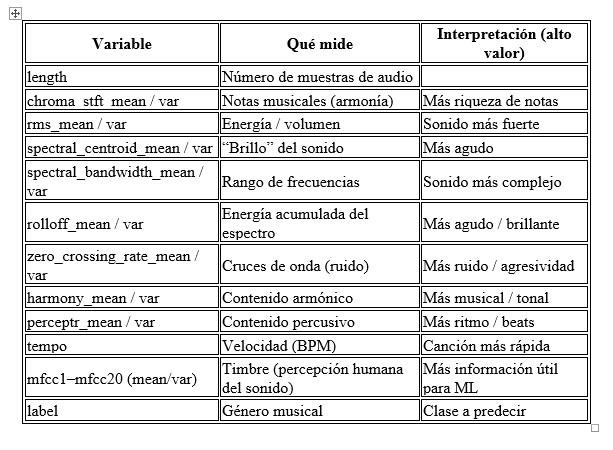

In [ ]:
#Estudiamos el tipo de variable y si existen nulos
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 60 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   filename                 1000 non-null   object 
 1   length                   1000 non-null   int64  
 2   chroma_stft_mean         1000 non-null   float64
 3   chroma_stft_var          1000 non-null   float64
 4   rms_mean                 1000 non-null   float64
 5   rms_var                  1000 non-null   float64
 6   spectral_centroid_mean   1000 non-null   float64
 7   spectral_centroid_var    1000 non-null   float64
 8   spectral_bandwidth_mean  1000 non-null   float64
 9   spectral_bandwidth_var   1000 non-null   float64
 10  rolloff_mean             1000 non-null   float64
 11  rolloff_var              1000 non-null   float64
 12  zero_crossing_rate_mean  1000 non-null   float64
 13  zero_crossing_rate_var   1000 non-null   float64
 14  harmony_mean             

Primeros vistazos a la tabla general con head, tail y sample

In [ ]:
df.head()

,filename,length,chroma_stft_mean,chroma_stft_var,rms_mean,rms_var,spectral_centroid_mean,spectral_centroid_var,spectral_bandwidth_mean,spectral_bandwidth_var,...,mfcc16_var,mfcc17_mean,mfcc17_var,mfcc18_mean,mfcc18_var,mfcc19_mean,mfcc19_var,mfcc20_mean,mfcc20_var,label
0,blues.00000.wav,661794,0.350088,0.088757,0.130228,0.002827,1784.165850,129774.064525,2002.449060,85882.761315,...,52.420910,-1.690215,36.524071,-0.408979,41.597103,-2.303523,55.062923,1.221291,46.936035,blues
1,blues.00001.wav,661794,0.340914,0.094980,0.095948,0.002373,1530.176679,375850.073649,2039.036516,213843.755497,...,55.356403,-0.731125,60.314529,0.295073,48.120598,-0.283518,51.106190,0.531217,45.786282,blues
2,blues.00002.wav,661794,0.363637,0.085275,0.175570,0.002746,1552.811865,156467.643368,1747.702312,76254.192257,...,40.598766,-7.729093,47.639427,-1.816407,52.382141,-3.439720,46.639660,-2.231258,30.573025,blues
3,blues.00003.wav,661794,0.404785,0.093999,0.141093,0.006346,1070.106615,184355.942417,1596.412872,166441.494769,...,44.427753,-3.319597,50.206673,0.636965,37.319130,-0.619121,37.259739,-3.407448,31.949339,blues
4,blues.00004.wav,661794,0.308526,0.087841,0.091529,0.002303,1835.004266,343399.939274,1748.172116,88445.209036,...,86.099236,-5.454034,75.269707,-0.916874,53.613918,-4.404827,62.910812,-11.703234,55.195160,blues


In [ ]:
df.tail()

,filename,length,chroma_stft_mean,chroma_stft_var,rms_mean,rms_var,spectral_centroid_mean,spectral_centroid_var,spectral_bandwidth_mean,spectral_bandwidth_var,...,mfcc16_var,mfcc17_mean,mfcc17_var,mfcc18_mean,mfcc18_var,mfcc19_mean,mfcc19_var,mfcc20_mean,mfcc20_var,label
995,rock.00095.wav,661794,0.352063,0.080487,0.079486,0.000345,2008.149458,282174.689224,2106.541053,88609.749506,...,45.050526,-13.289984,41.754955,2.484145,36.778877,-6.713265,54.866825,-1.193787,49.950665,rock
996,rock.00096.wav,661794,0.398687,0.075086,0.076458,0.000588,2006.843354,182114.709510,2068.942009,82426.016726,...,33.851742,-10.848309,39.395096,1.881229,32.010040,-7.461491,39.196327,-2.795338,31.773624,rock
997,rock.00097.wav,661794,0.432142,0.075268,0.081651,0.000322,2077.526598,231657.968040,1927.293153,74717.124394,...,33.597008,-12.845291,36.367264,3.440978,36.001110,-12.588070,42.502201,-2.106337,29.865515,rock
998,rock.00098.wav,661794,0.362485,0.091506,0.083860,0.001211,1398.699344,240318.731073,1818.450280,109090.207161,...,46.324894,-4.416050,43.583942,1.556207,34.331261,-5.041897,47.227180,-3.590644,41.299088,rock
999,rock.00099.wav,661794,0.358401,0.085884,0.054454,0.000336,1609.795082,422203.216152,1797.213044,120115.632927,...,59.167755,-7.069775,73.760391,0.028346,76.504326,-2.025783,72.189316,1.155239,49.662510,rock


In [ ]:
df.sample(5)

,filename,length,chroma_stft_mean,chroma_stft_var,rms_mean,rms_var,spectral_centroid_mean,spectral_centroid_var,spectral_bandwidth_mean,spectral_bandwidth_var,...,mfcc16_var,mfcc17_mean,mfcc17_var,mfcc18_mean,mfcc18_var,mfcc19_mean,mfcc19_var,mfcc20_mean,mfcc20_var,label
653,metal.00053.wav,661794,0.492827,0.078170,0.227499,0.002003,2906.766679,118853.054261,2374.746552,46714.416789,...,26.913851,-5.390154,26.726738,3.408915,24.453365,-6.927285,29.771788,6.545909,26.920095,metal
381,disco.00081.wav,661504,0.358245,0.094388,0.078765,0.002306,2292.713829,614938.226035,2208.658532,158470.433441,...,100.521622,-6.875402,103.755730,-0.713053,111.339401,-6.418620,82.547493,-0.562401,87.300720,disco
407,hiphop.00007.wav,661504,0.432617,0.088556,0.263999,0.009428,2046.591597,498193.460103,2268.578382,210136.791545,...,50.536541,-3.173525,67.377480,1.816087,38.427059,-2.566935,31.217880,0.108951,42.227978,hiphop
227,country.00027.wav,661794,0.391828,0.082007,0.116644,0.001036,2011.642324,181183.923028,2140.356810,168320.144926,...,38.010822,-10.224055,42.249950,-10.540270,40.994244,-5.738250,37.160957,-7.300997,42.393173,country
371,disco.00071.wav,661504,0.435500,0.082165,0.098152,0.001563,2808.912510,358338.786007,2530.920633,51028.040414,...,38.381775,-12.227236,31.719463,2.872978,46.252258,-4.684423,43.916496,8.169663,60.414612,disco


Confirmamos que no existen nulos

In [ ]:
df.isna().sum()

,0
filename,0
length,0
chroma_stft_mean,0
chroma_stft_var,0
rms_mean,0
rms_var,0
spectral_centroid_mean,0
spectral_centroid_var,0
spectral_bandwidth_mean,0
spectral_bandwidth_var,0


Es importante identificar los valores duplicados en el dataframe por si se deben a errores en la propia base de datos.

In [ ]:
# Cuantas filas tenemos duplicadas en el dataset
num_dupl = df.duplicated().sum()
print('Duplicados: ', num_dupl)

Duplicados:  0


Estadísticos básicos

In [ ]:
#Aplicamos describe en la variable lenght
df["length"].describe()

,length
count,1000.000000
mean,662030.846000
std,1784.073992
min,660000.000000
25%,661504.000000
50%,661794.000000
75%,661794.000000
max,675808.000000


In [ ]:
porcentaje_de_variabilidad = (df['length'].std() / df['length'].mean()) * 100

print(f"El porcentaje de variabilidad de length es: {porcentaje_de_variabilidad:.2f}%")

El porcentaje de variabilidad de length es: 0.27%


**Conclusión:** length representa el número de muestras de audio del fragmento y presenta una variabilidad muy reducida, ya que los registros corresponden aproximadamente a 30 segundos de audio. Aunque existen pequeñas diferencias en el número de muestras, su variabilidad relativa es de aproximadamente un 0,27 %, por lo que probablemente tenga poca capacidad discriminativa para distinguir géneros musicales.

In [ ]:
#Aplicamos .describe en cada columna que termine en .mean agrupando además por género
cols_mean = [col for col in df.columns if col.endswith("mean")]
resultado = df.groupby("label")[cols_mean].describe().reset_index()
display(resultado)

label chroma_stft_mean                                          \
                        count      mean       std       min       25%   
0      blues            100.0  0.341429  0.058422  0.233398  0.290680   
1  classical            100.0  0.263542  0.044096  0.181137  0.234180   
2    country            100.0  0.343812  0.040923  0.221440  0.316590   
3      disco            100.0  0.415643  0.047113  0.220175  0.388475   
4     hiphop            100.0  0.454319  0.047097  0.340300  0.424750   
5       jazz            100.0  0.296643  0.054470  0.171939  0.264600   
6      metal            100.0  0.479235  0.051745  0.341908  0.441148   
7        pop            100.0  0.397632  0.057094  0.225680  0.355804   
8     reggae            100.0  0.408247  0.059162  0.271977  0.370921   
9       rock            100.0  0.386315  0.044651  0.255701  0.358317   

                                rms_mean  ... mfcc19_mean             \
        50%       75%       max    count  ...         75%        max   
0  0.339091  0.388519  0.466529    100.0  ...   -0.879806   7.541378   
1  0.260931  0.284032  0.437906    100.0  ...    1.119779  14.694924   
2  0.347686  0.373390  0.437655    100.0  ...   -0.984005   6.230408   
3  0.416673  0.441251  0.568171    100.0  ...   -0.439226   4.695799   
4  0.452387  0.483018  0.583706    100.0  ...    0.275079  14.656418   
5  0.285688  0.328401  0.441749    100.0  ...    1.000091   7.883079   
6  0.477866  0.510582  0.636210    100.0  ...   -2.993954   4.240802   
7  0.402106  0.435769  0.522806    100.0  ...    2.328774   9.181066   
8  0.396217  0.447242  0.663685    100.0  ...   -0.404668   4.745884   
9  0.390181  0.415849  0.488327    100.0  ...   -1.875373   3.858559   

  mfcc20_mean                                                               \
        count      mean       std        min       25%       50%       75%   
0       100.0 -2.793275  5.299195 -19.929634 -4.365721 -2.052564  0.574133   
1       100.0 -1.066748  3.820228  -8.062643 -3.719290 -1.440786  1.352722   
2       100.0 -3.055206  3.322862 -10.711282 -4.821198 -2.894463 -1.249436   
3       100.0  0.480941  3.188322  -5.977642 -1.649209 -0.044634  2.849073   
4       100.0 -0.806001  3.605825  -7.355111 -3.313987 -1.193096  1.164126   
5       100.0 -2.088557  3.577407 -10.596965 -4.794560 -2.036435  0.332822   
6       100.0  1.264175  3.851246  -9.290500 -1.555018  1.407859  3.684819   
7       100.0  0.307300  2.847948  -6.399621 -1.796094  0.298872  1.947883   
8       100.0 -1.607359  3.068098 -12.712146 -3.084116 -1.350421  0.219724   
9       100.0 -1.588750  2.832164  -8.440157 -3.307942 -1.420835 -0.059638   

              
         max  
0   6.646699  
1  11.523016  
2   6.310607  
3  10.207119  
4  15.369627  
5   9.826226  
6   9.080583  
7   8.227995  
8   5.303598  
9   7.538990  

[10 rows x 225 columns]

No es muy legible, resumimos solo con los estadísticos de media y desviación estándar

In [ ]:
#Resumen de la info más relevante para diferenciar entre géneros
resumen = (df.groupby("label")[cols_mean].agg(["mean", "std"])).reset_index()

display(resumen)

label chroma_stft_mean            rms_mean            \
                         mean       std      mean       std   
0      blues         0.341429  0.058422  0.136067  0.051978   
1  classical         0.263542  0.044096  0.042920  0.036830   
2    country         0.343812  0.040923  0.125988  0.049196   
3      disco         0.415643  0.047113  0.136296  0.043304   
4     hiphop         0.454319  0.047097  0.178344  0.059893   
5       jazz         0.296643  0.054470  0.086648  0.045733   
6      metal         0.479235  0.051745  0.153478  0.064175   
7        pop         0.397632  0.057094  0.199734  0.058004   
8     reggae         0.408247  0.059162  0.122503  0.050663   
9       rock         0.386315  0.044651  0.127320  0.043781   

  spectral_centroid_mean             spectral_bandwidth_mean              \
                    mean         std                    mean         std   
0            1727.584661  515.526151             1931.447105  330.214368   
1            1353.878837  348.164268             1521.709862  254.236037   
2            1896.210622  575.912832             2099.535390  445.278799   
3            2619.852229  478.806962             2513.251591  357.496881   
4            2524.518523  479.286475             2513.452483  347.197818   
5            1792.360097  680.641159             2021.001244  567.440784   
6            2602.181204  368.566462             2242.538687  201.325887   
7            3073.549538  582.121261             3008.195592  316.946183   
8            2185.016755  626.596310             2311.453709  390.704772   
9            2242.656512  483.801285             2262.825036  347.836249   

  rolloff_mean  ... mfcc16_mean           mfcc17_mean           mfcc18_mean  \
          mean  ...        mean       std        mean       std        mean   
0  3636.877154  ...    0.193491  6.480287   -7.217955  4.084105   -1.448949   
1  2482.325982  ...    1.044787  4.331590    0.176529  4.187054    0.571998   
2  3949.577166  ...   -0.388173  4.656351   -5.618285  3.494105   -0.365908   
3  5519.791820  ...    1.243687  3.679722   -4.326491  4.029805    1.130248   
4  5333.623851  ...    2.596768  4.195870   -2.960372  2.841137    1.384509   
5  3750.174280  ...    0.487133  4.465476   -1.453946  3.782823   -0.955960   
6  5125.230255  ...    5.450559  3.172143   -7.969246  2.774385    2.885922   
7  6654.772975  ...   -0.972551  3.606330   -0.375791  3.570188    0.526494   
8  4593.939352  ...    0.976151  3.668015   -3.641866  3.789366    1.054487   
9  4669.180208  ...    0.849587  3.504352   -6.272861  4.005702    0.294123   

            mfcc19_mean           mfcc20_mean            
        std        mean       std        mean       std  
0  4.443170   -3.606209  4.648279   -2.793275  5.299195  
1  3.856687   -1.065244  3.471303   -1.066748  3.820228  
2  4.303461   -2.816718  3.153193   -3.055206  3.322862  
3  3.529752   -2.960387  3.379468    0.480941  3.188322  
4  4.072919   -1.739940  3.468336   -0.806001  3.605825  
5  3.169192   -1.144374  3.397880   -2.088557  3.577407  
6  2.905122   -4.740642  3.493641    1.264175  3.851246  
7  3.514286    0.847990  2.762064    0.307300  2.847948  
8  3.449584   -2.160267  2.766815   -1.607359  3.068098  
9  3.479688   -3.901818  3.464184   -1.588750  2.832164  

[10 rows x 57 columns]

In [ ]:
#Trasponemos para que sea aún más legible
resumen.T

0            1            2  \
label                               blues    classical      country   
chroma_stft_mean        mean     0.341429     0.263542     0.343812   
                        std      0.058422     0.044096     0.040923   
rms_mean                mean     0.136067      0.04292     0.125988   
                        std      0.051978      0.03683     0.049196   
spectral_centroid_mean  mean  1727.584661  1353.878837  1896.210622   
                        std    515.526151   348.164268   575.912832   
spectral_bandwidth_mean mean  1931.447105  1521.709862   2099.53539   
                        std    330.214368   254.236037   445.278799   
rolloff_mean            mean  3636.877154  2482.325982  3949.577166   
                        std   1160.651549   751.014031  1293.225995   
zero_crossing_rate_mean mean     0.078969     0.077611       0.0834   
                        std      0.035213     0.026035     0.030207   
harmony_mean            mean    -0.000458    -0.000246    -0.000014   
                        std      0.001476     0.000608     0.000054   
perceptr_mean           mean    -0.000564    -0.000182    -0.000128   
                        std      0.001429     0.000407     0.000441   
mfcc1_mean              mean  -164.594262  -320.051968  -145.025413   
                        std     84.631938   101.399657    73.024778   
mfcc2_mean              mean   113.939874   141.267681   113.491611   
                        std     19.907417    23.791085    28.644703   
mfcc3_mean              mean    -7.386837   -19.677586    -8.270216   
                        std     19.269747     20.68365    15.809943   
mfcc4_mean              mean    46.612982    23.265183    37.651736   
                        std     14.901129    11.394066    11.610289   
mfcc5_mean              mean     -3.64061     -2.40079     1.679887   
                        std     15.377298     7.380003    10.410677   
mfcc6_mean              mean    22.343309     2.226187    11.068756   
                        std      9.135949     8.426275     9.983549   
mfcc7_mean              mean   -10.675595    -7.693913    -4.436839   
                        std     10.163364     5.120361     8.409629   
mfcc8_mean              mean    13.910228    -0.462536     7.982941   
                        std      8.664767     9.357104     8.145254   
mfcc9_mean              mean    -12.44413    -6.419804    -9.061342   
                        std      6.297761     5.429308     6.849833   
mfcc10_mean             mean     8.172068     1.217143     6.274004   
                        std      7.244686      7.70001     6.781841   
mfcc11_mean             mean    -9.752592    -5.915462    -7.055157   
                        std      8.313793     4.636466     5.725484   
mfcc12_mean             mean     3.541161    -0.574115     3.019775   
                        std      6.992332     5.661297     5.226912   
mfcc13_mean             mean    -8.048941    -2.066264    -5.404078   
                        std      6.701623     4.521278     4.768306   
mfcc14_mean             mean     1.289309    -0.635426    -0.231192   
                        std      5.567604     4.704647     4.256889   
mfcc15_mean             mean    -6.827298    -0.484038    -4.661622   
                        std      5.347177     4.264121     3.722284   
mfcc16_mean             mean     0.193491     1.044787    -0.388173   
                        std      6.480287      4.33159     4.656351   
mfcc17_mean             mean    -7.217955     0.176529    -5.618285   
                        std      4.084105     4.187054     3.494105   
mfcc18_mean             mean    -1.448949     0.571998    -0.365908   
                        std       4.44317     3.856687     4.303461   
mfcc19_mean             mean    -3.606209    -1.065244    -2.816718   
                        std      4.648279     3.471303     3.153193   
mfcc20_mean             mean    -2.793275    -1.066748    -3.055

Estudio de outliers de las medias de las variables, las columnas acabadas en .mean

In [ ]:
Q1 = df[cols_mean].quantile(0.25)
Q3 = df[cols_mean].quantile(0.75)
IQR = Q3 - Q1

# Identificación de outliers
mask = (df[cols_mean] > (Q3 + 1.5 * IQR)) | (df[cols_mean] < (Q1 - 1.5 * IQR))
mask = (df[cols_mean] > (Q3 + 1.5 * IQR)) | (df[cols_mean] < (Q1 - 1.5 * IQR))
outliers = df[mask.any(axis=1)]
display(outliers)
display(mask.sum())




,filename,length,chroma_stft_mean,chroma_stft_var,rms_mean,rms_var,spectral_centroid_mean,spectral_centroid_var,spectral_bandwidth_mean,spectral_bandwidth_var,...,mfcc16_var,mfcc17_mean,mfcc17_var,mfcc18_mean,mfcc18_var,mfcc19_mean,mfcc19_var,mfcc20_mean,mfcc20_var,label
4,blues.00004.wav,661794,0.308526,0.087841,0.091529,0.002303,1835.004266,343399.939274,1748.172116,88445.209036,...,86.099236,-5.454034,75.269707,-0.916874,53.613918,-4.404827,62.910812,-11.703234,55.195160,blues
7,blues.00007.wav,661794,0.307955,0.092903,0.131822,0.005531,1451.667066,449568.162454,1577.270941,168211.938804,...,70.438438,-10.568935,52.090893,-10.784515,60.461330,-4.690678,65.547516,-8.630722,56.401436,blues
23,blues.00023.wav,661794,0.280823,0.091157,0.102035,0.003566,1209.987863,131778.372556,1497.691564,51624.607823,...,45.263859,-2.985965,66.982353,-1.386169,82.635551,7.541378,93.393692,-3.035723,74.014458,blues
29,blues.00029.wav,661794,0.280357,0.105621,0.124736,0.004812,1648.835169,712342.593798,2189.985865,185296.921351,...,84.208382,-11.384393,98.334000,-6.723499,96.627716,-10.013582,74.162971,-14.026128,77.931458,blues
30,blues.00030.wav,661794,0.263194,0.094373,0.170062,0.003188,1379.189382,550980.401777,2004.210663,269867.234656,...,85.731583,-15.332039,78.006058,-9.656509,97.278809,-10.089768,55.413876,-17.826880,91.008377,blues
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
987,rock.00087.wav,661794,0.392848,0.076381,0.165843,0.001031,2334.498686,113084.869493,2208.043898,44310.693005,...,31.383272,-11.953029,24.069769,0.898219,45.988560,-0.470914,54.490551,1.297606,38.836918,rock
988,rock.00088.wav,661794,0.408240,0.089074,0.089583,0.001480,2590.730306,305922.999830,2078.710859,77068.731362,...,49.094765,-6.792089,68.375999,4.458619,89.482803,0.244446,94.910492,0.444432,106.106804,rock
990,rock.00090.wav,661794,0.255701,0.090605,0.154724,0.001484,2495.723202,273423.385148,2249.878670,37750.184314,...,130.468796,0.676879,199.176361,9.795698,172.235184,-2.125449,180.240295,0.590357,148.713028,rock
992,rock.00092.wav,661794,0.416625,0.073754,0.106913,0.000215,2471.353263,108646.359346,2102.155349,25982.821385,...,25.989548,-15.053774,21.858854,-1.606128,23.771255,-16.089317,21.082539,-2.186192,23.541199,rock


,0
chroma_stft_mean,3
rms_mean,5
spectral_centroid_mean,1
spectral_bandwidth_mean,1
rolloff_mean,0
zero_crossing_rate_mean,6
harmony_mean,239
perceptr_mean,154
mfcc1_mean,27
mfcc2_mean,4


In [ ]:
#Identificación de outliers por porcentaje
porcentaje_outliers = (mask.sum() / len(df)) * 100
display(porcentaje_outliers.sort_values(ascending=False))

,0
harmony_mean,23.9
perceptr_mean,15.4
mfcc1_mean,2.7
mfcc20_mean,2.3
mfcc19_mean,1.5
mfcc18_mean,1.2
mfcc16_mean,0.9
mfcc17_mean,0.9
zero_crossing_rate_mean,0.6
mfcc3_mean,0.5


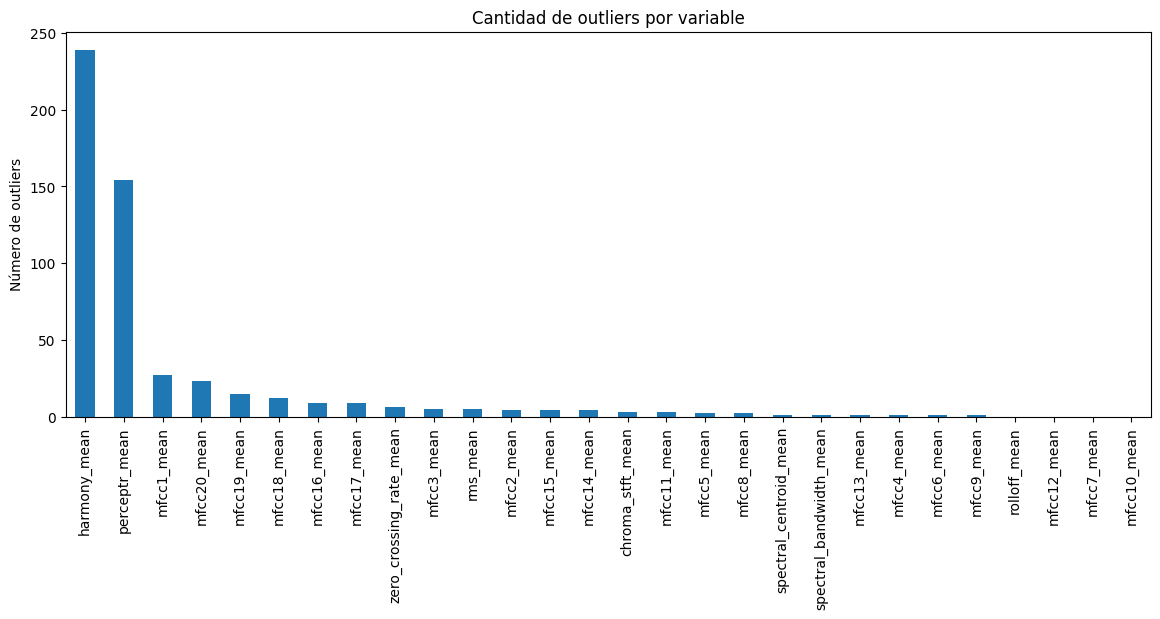

In [ ]:
mask.sum().sort_values(ascending=False).plot(
    kind="bar",
    figsize=(14,5)
)

plt.title("Cantidad de outliers por variable")
plt.ylabel("Número de outliers")
plt.xticks(rotation=90)
plt.show()

Estudio de las variables con más porcentaje de outliers, empezando por la de mayor porcentaje

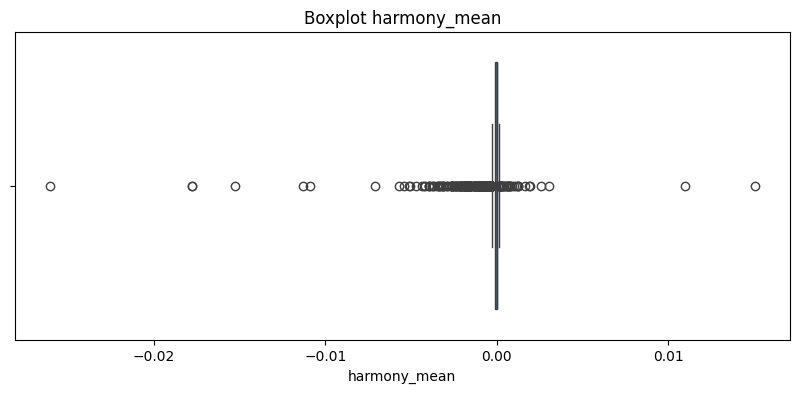

In [ ]:
plt.figure(figsize=(10,4))
sns.boxplot(x=df["harmony_mean"])

plt.title("Boxplot harmony_mean")
plt.show()

In [ ]:
fig = px.histogram(
    df,
    x="harmony_mean",
    nbins=40,
    opacity=0.7)

fig.update_layout(
    title="Distribución de harmony_mean",
    xaxis_title="harmony_mean",
    yaxis_title="Frecuencia",
    height=500,
    width=1000)

fig.show()

Harmony es una variable que tiene un histograma con colas largas pero que parecen naturales, no parece que haya grupos claramente separados, es decir, que no parecen datos erróneos o mal medidos, de hecho el rango es bastante pequeño de -0.025 a 0.015. Como es una variable que mide el contenido armónico de la música haremos una comprobación más por si acaso se refieren a un mismo género


In [ ]:
#Primero sacamos los outliers solo de Harmony y los contamos por género
Q1_h = df["harmony_mean"].quantile(0.25)
Q3_h = df["harmony_mean"].quantile(0.75)
IQR_h = Q3_h - Q1_h

mask_harmony = ((df["harmony_mean"] < (Q1_h - 1.5 * IQR_h)) | (df["harmony_mean"] > (Q3_h + 1.5 * IQR_h)))
outliers_genero = (df[mask_harmony]["label"].value_counts())

display(outliers_genero)

,count
label,
classical,42
rock,39
reggae,34
metal,33
jazz,28
disco,21
hiphop,16
pop,13
blues,12


In [ ]:
#Ahora lo vemos en porcentaje
porcentaje_genero = (df[mask_harmony].groupby("label").size()/ df.groupby("label").size()* 100).sort_values(ascending=False)

display(porcentaje_genero)

,0
label,
classical,42.0
rock,39.0
reggae,34.0
metal,33.0
jazz,28.0
disco,21.0
hiphop,16.0
pop,13.0
blues,12.0


Queda claro que si trabajamos SIN outliers, al menos en cuanto a la varibale Harmony, vamos a eliminar un gran porcentaje de datos de casi todos los géneros por lo que trabajaremos con el dataset

#Elección de variables para ML

In [ ]:
#Identificación de la variable objetivo
var_obj ='label'

In [ ]:
#Sacamos el histograma de nuestra variable objetivo
fig = px.histogram(
    df,
    x="label",
    nbins=40,
    opacity=0.7)

fig.update_layout(
    title="Distribución de label",
    xaxis_title="label",
    yaxis_title="Frecuencia",
    height=500,
    width=1000)

fig.show()

#Esto nos dice que nuestro problema está balanceado, tenemos el mismo número de datos para cada uno de los géneros

##Método de las medias

In [ ]:
#Para elegir las 5 variables más importantes con outliers, saco las que haya una mayor diferencia entre su media mínima y máxima (las que más varían entre géneros)
cols_mean = [col for col in df.columns if col.endswith("mean")]

medias = df.groupby("label")[cols_mean].mean()

diferencia = medias.max() - medias.min()

top5 = diferencia.sort_values(ascending=False).head(5)
print(top5)



rolloff_mean               4172.446993
spectral_centroid_mean     1719.670701
spectral_bandwidth_mean    1486.485731
mfcc1_mean                  256.993578
mfcc2_mean                   73.302535
dtype: float64


Coinciden las variables más destacadas identificadas en el dataframe sin outliers con las más destacadas con outliers. Vamos a trabajar con outliers pues pueden

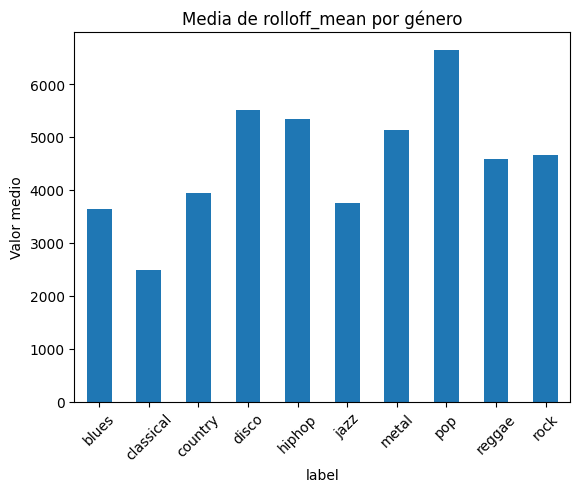

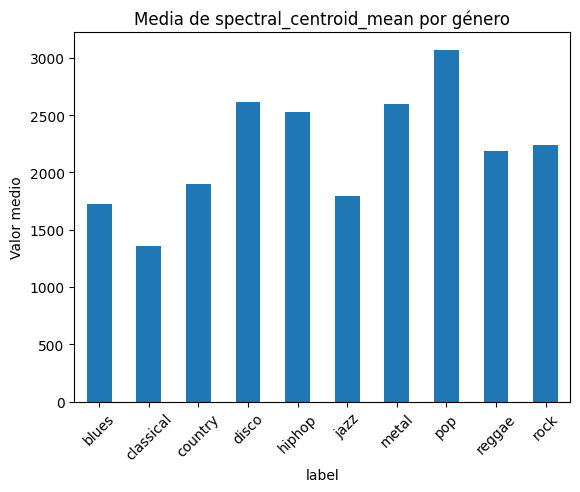

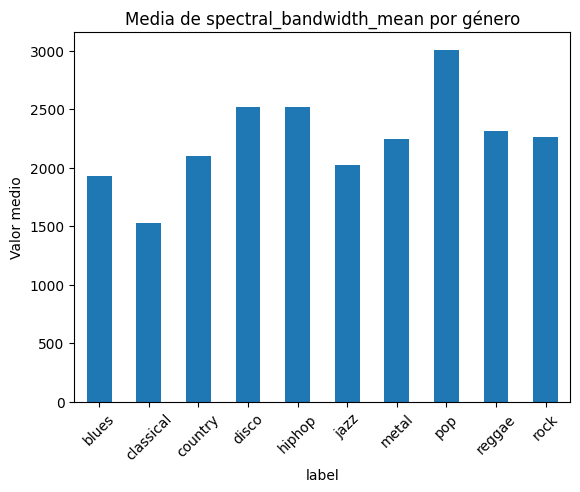

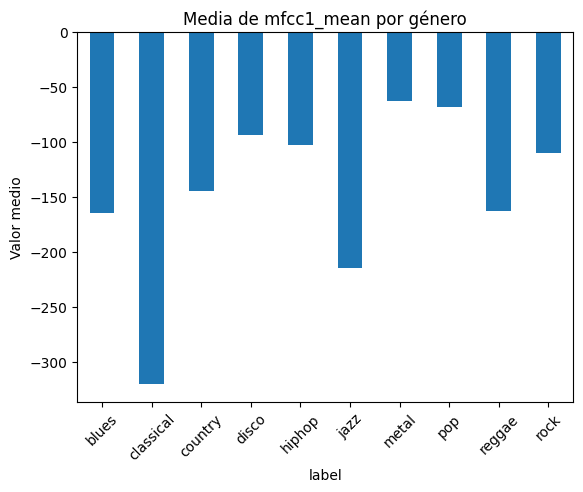

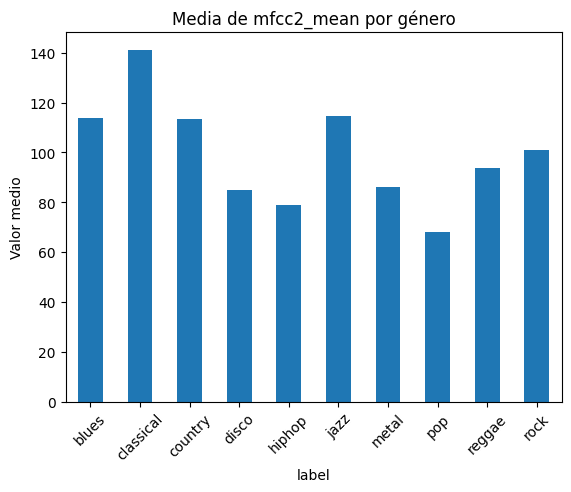

In [ ]:
#Saco gráfico de estas 5 variables para comparar entre géneros
top5_cols = top5.index
for col in top5_cols:
    df.groupby("label")[col].mean().plot(kind="bar")

    plt.title(f"Media de {col} por género")
    plt.ylabel("Valor medio")
    plt.xticks(rotation=45)

    plt.show()

In [ ]:
#Saco el ranking para posicionar los géneros en orden
for col in top5_cols:
    print(f"\n🔹 Ranking por {col}")

    ranking = df.groupby("label")[col].mean().sort_values(ascending=False).round(2)

    display(ranking)


🔹 Ranking por rolloff_mean


,rolloff_mean
label,
pop,6654.77
disco,5519.79
hiphop,5333.62
metal,5125.23
rock,4669.18
reggae,4593.94
country,3949.58
jazz,3750.17
blues,3636.88



🔹 Ranking por spectral_centroid_mean


,spectral_centroid_mean
label,
pop,3073.55
disco,2619.85
metal,2602.18
hiphop,2524.52
rock,2242.66
reggae,2185.02
country,1896.21
jazz,1792.36
blues,1727.58



🔹 Ranking por spectral_bandwidth_mean


,spectral_bandwidth_mean
label,
pop,3008.20
hiphop,2513.45
disco,2513.25
reggae,2311.45
rock,2262.83
metal,2242.54
country,2099.54
jazz,2021.00
blues,1931.45



🔹 Ranking por mfcc1_mean


,mfcc1_mean
label,
metal,-63.06
pop,-67.85
disco,-93.72
hiphop,-103.01
rock,-110.32
country,-145.03
reggae,-162.55
blues,-164.59
jazz,-214.55



🔹 Ranking por mfcc2_mean


,mfcc2_mean
label,
classical,141.27
jazz,114.41
blues,113.94
country,113.49
rock,101.10
reggae,93.60
metal,85.92
disco,84.89
hiphop,78.96


In [ ]:
#Comprobamos la correlación entre variables para comprobar si hay variables que nos dan imformación redundante
corr_top5 = df[top5_cols].corr()

display(corr_top5)

,rolloff_mean,spectral_centroid_mean,spectral_bandwidth_mean,mfcc1_mean,mfcc2_mean
rolloff_mean,1.000000,0.979637,0.956189,0.721943,-0.934302
spectral_centroid_mean,0.979637,1.000000,0.904435,0.721006,-0.940180
spectral_bandwidth_mean,0.956189,0.904435,1.000000,0.648602,-0.896652
mfcc1_mean,0.721943,0.721006,0.648602,1.000000,-0.639212
mfcc2_mean,-0.934302,-0.940180,-0.896652,-0.639212,1.000000


**Conclusiones:** Las diferencias observadas en estas variables sugieren que el pop tiende a presentar un mayor contenido de frecuencias altas y una distribución espectral más amplia, asociada a sonidos más brillantes y ricos. En cambio, la música clásica muestra valores más bajos en estas métricas, lo que indica una mayor concentración en frecuencias medias y graves y una menor dispersión espectral.

Spectral_centroid_mean, spectral_bandwidth_mean y rolloff_mean presentan una correlación muy alta entre sí, lo que indica que capturan información espectral similar relacionada con la distribución de frecuencias y la brillantez del sonido. Por tanto, en un modelo de clasificación de géneros musicales podría ser suficiente utilizar una de estas variables para reducir redundancia sin perder demasiada información.

Por último, mfcc2_mean tiene correlaciones negativas muy fuertes con las variables espectrales. Eso sugiere que aporta información distinta y probablemente muy útil para clasificación, así que esa variable sí parece especialmente valiosa mantenerla.

##Método por visualización

In [ ]:
# Primero Separamos columnas cualitativas y cuantitativas y comprobamos que se ha hecho bien:
columnas_object = df.select_dtypes(include=['object']).columns
columnas_numeric = df.select_dtypes(include=np.number).columns
columnas_object


Index(['filename', 'label'], dtype='object')

In [ ]:
#Sacamos los valores únicos de las variables numéricas por si nos interesa tratarlas como categóricas
numero_maximo_registros = 12
df_nunique_num = df[columnas_numeric].nunique().sort_values(ascending=False)
fig_nunique_num = px.bar(df_nunique_num.tail(numero_maximo_registros), orientation='h', title='Valore Unicos Más Pequeños Var. Numericas', labels={'index':'Variables Numericas'})
fig_nunique_num.update(layout_showlegend=False)

#Vemos que son muchos valores únicos como para tratarlas como categóricas

In [ ]:
#Distribución de las variables numéricas. Obtenemos una automatización de los gráficos para poder visualizarlos solo cambiando más abajo el nombre de la variable que elijamos
fig_dist_num = {}
for colum in columnas_numeric:
    fig_dist_num[colum] = px.histogram(df, x=colum, color_discrete_sequence=['darkblue'], title=colum)
    fig_dist_num[colum].update_traces(opacity=0.75)

In [ ]:
columnas_numeric

Index(['length', 'chroma_stft_mean', 'chroma_stft_var', 'rms_mean', 'rms_var',
       'spectral_centroid_mean', 'spectral_centroid_var',
       'spectral_bandwidth_mean', 'spectral_bandwidth_var', 'rolloff_mean',
       'rolloff_var', 'zero_crossing_rate_mean', 'zero_crossing_rate_var',
       'harmony_mean', 'harmony_var', 'perceptr_mean', 'perceptr_var', 'tempo',
       'mfcc1_mean', 'mfcc1_var', 'mfcc2_mean', 'mfcc2_var', 'mfcc3_mean',
       'mfcc3_var', 'mfcc4_mean', 'mfcc4_var', 'mfcc5_mean', 'mfcc5_var',
       'mfcc6_mean', 'mfcc6_var', 'mfcc7_mean', 'mfcc7_var', 'mfcc8_mean',
       'mfcc8_var', 'mfcc9_mean', 'mfcc9_var', 'mfcc10_mean', 'mfcc10_var',
       'mfcc11_mean', 'mfcc11_var', 'mfcc12_mean', 'mfcc12_var', 'mfcc13_mean',
       'mfcc13_var', 'mfcc14_mean', 'mfcc14_var', 'mfcc15_mean', 'mfcc15_var',
       'mfcc16_mean', 'mfcc16_var', 'mfcc17_mean', 'mfcc17_var', 'mfcc18_mean',
       'mfcc18_var', 'mfcc19_mean', 'mfcc19_var', 'mfcc20_mean', 'mfcc20_var'],
      dtype='

In [ ]:
#Cambiando el nombre de la variable podemos ir viendo una a una
fig_dist_num['harmony_var']

In [ ]:
#Observamos la relación de las variables numéricas con la variable objetivo creando otra automatización y poder verlas una a una
fig_box_plot = {}
for colum in columnas_numeric:
    fig_box_plot[colum] = px.box(df, x=colum, color=var_obj, orientation='h')


In [ ]:
#Cambiando el nombre de la variable podemos ir comprobando la relación una a una
fig_box_plot['mfcc12_mean']

**Conclusión:** Tras analizar los boxplots de las distintas variables, se observa un notable solapamiento entre las distribuciones de los géneros musicales, lo que indica que ninguna variable individual presenta suficiente capacidad discriminatoria por sí sola. Esto sugiere que la clasificación de géneros musicales requiere la combinación de varias características de audio para obtener una separación más precisa entre categorías.

A continuación, se estudiarán las correlaciones entre variables con el objetivo de identificar aquellas que aportan información similar y podrían resultar redundantes.

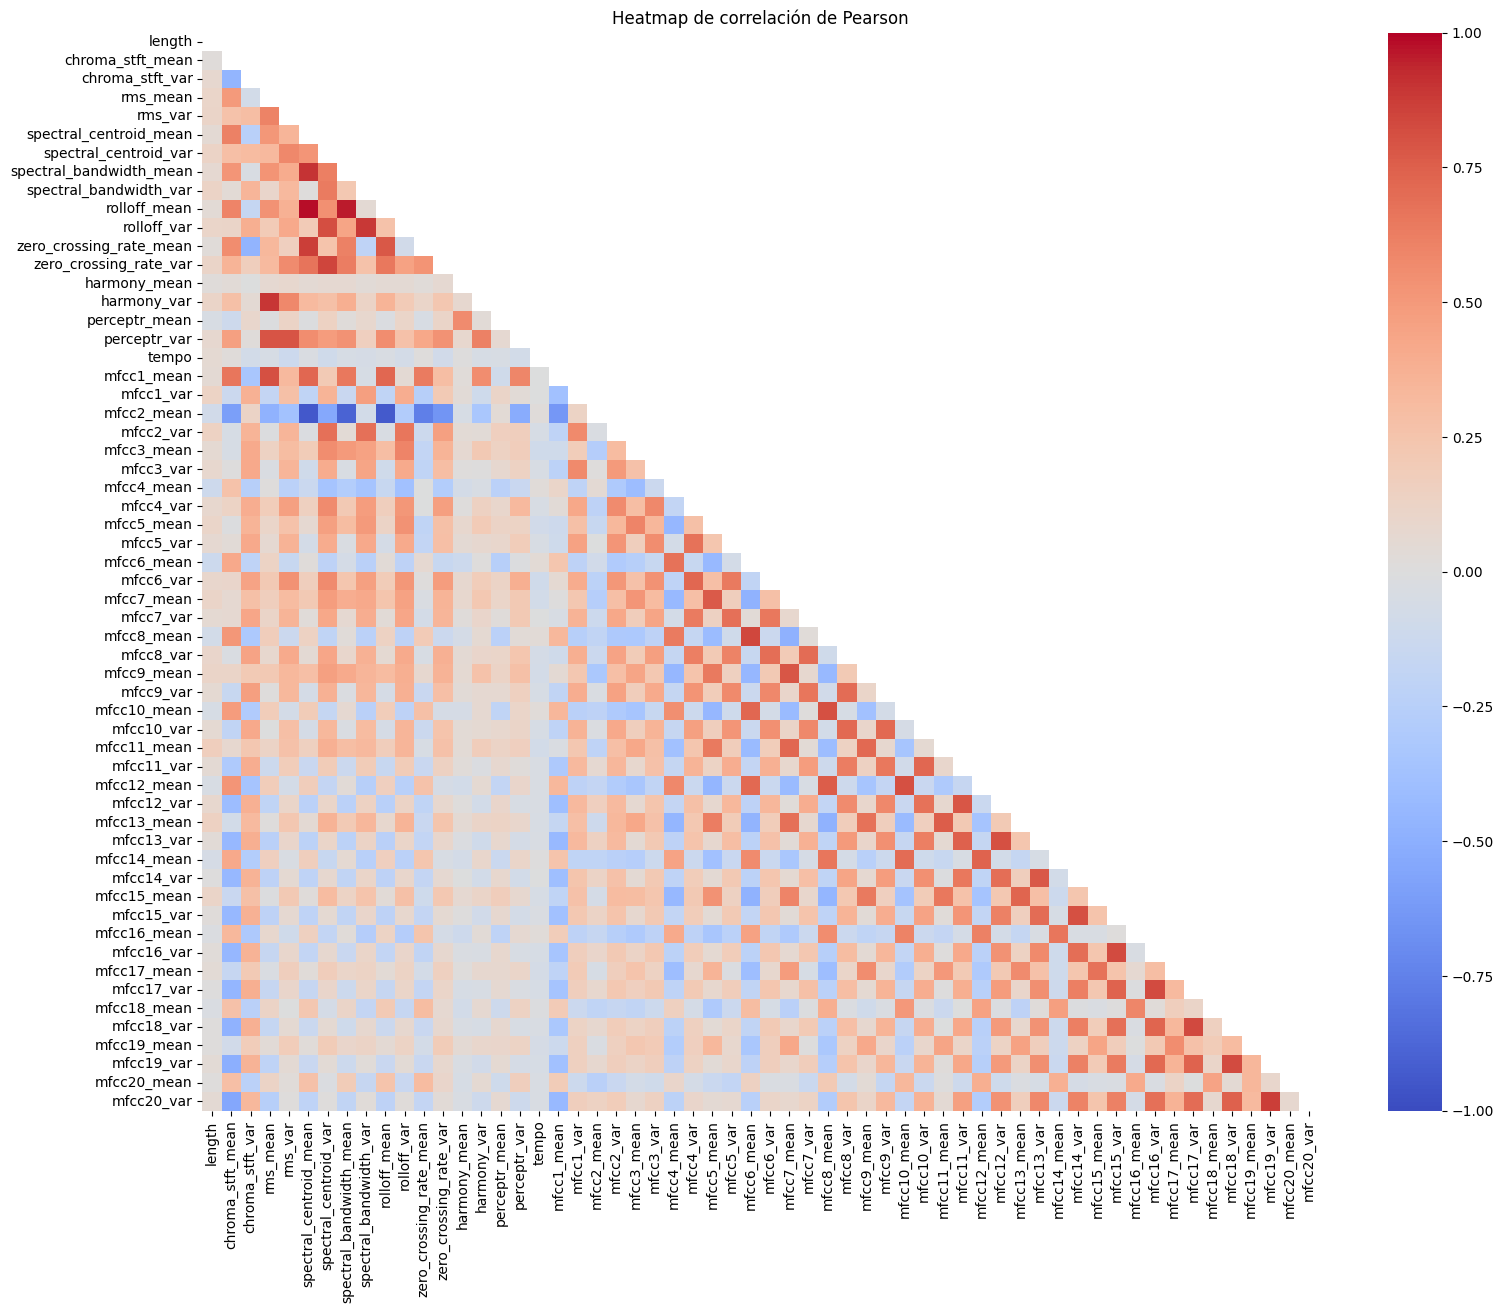

In [ ]:
#Comprobamos las correlaciones de todas las variables numéricas
corr = df[columnas_numeric].corr(method="pearson")

mask = np.triu(np.ones_like(corr, dtype=bool))


plt.figure(figsize=(18,14))

sns.heatmap(
    corr,
    mask=mask,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    annot=False
)

plt.title("Heatmap de correlación de Pearson")
plt.show()

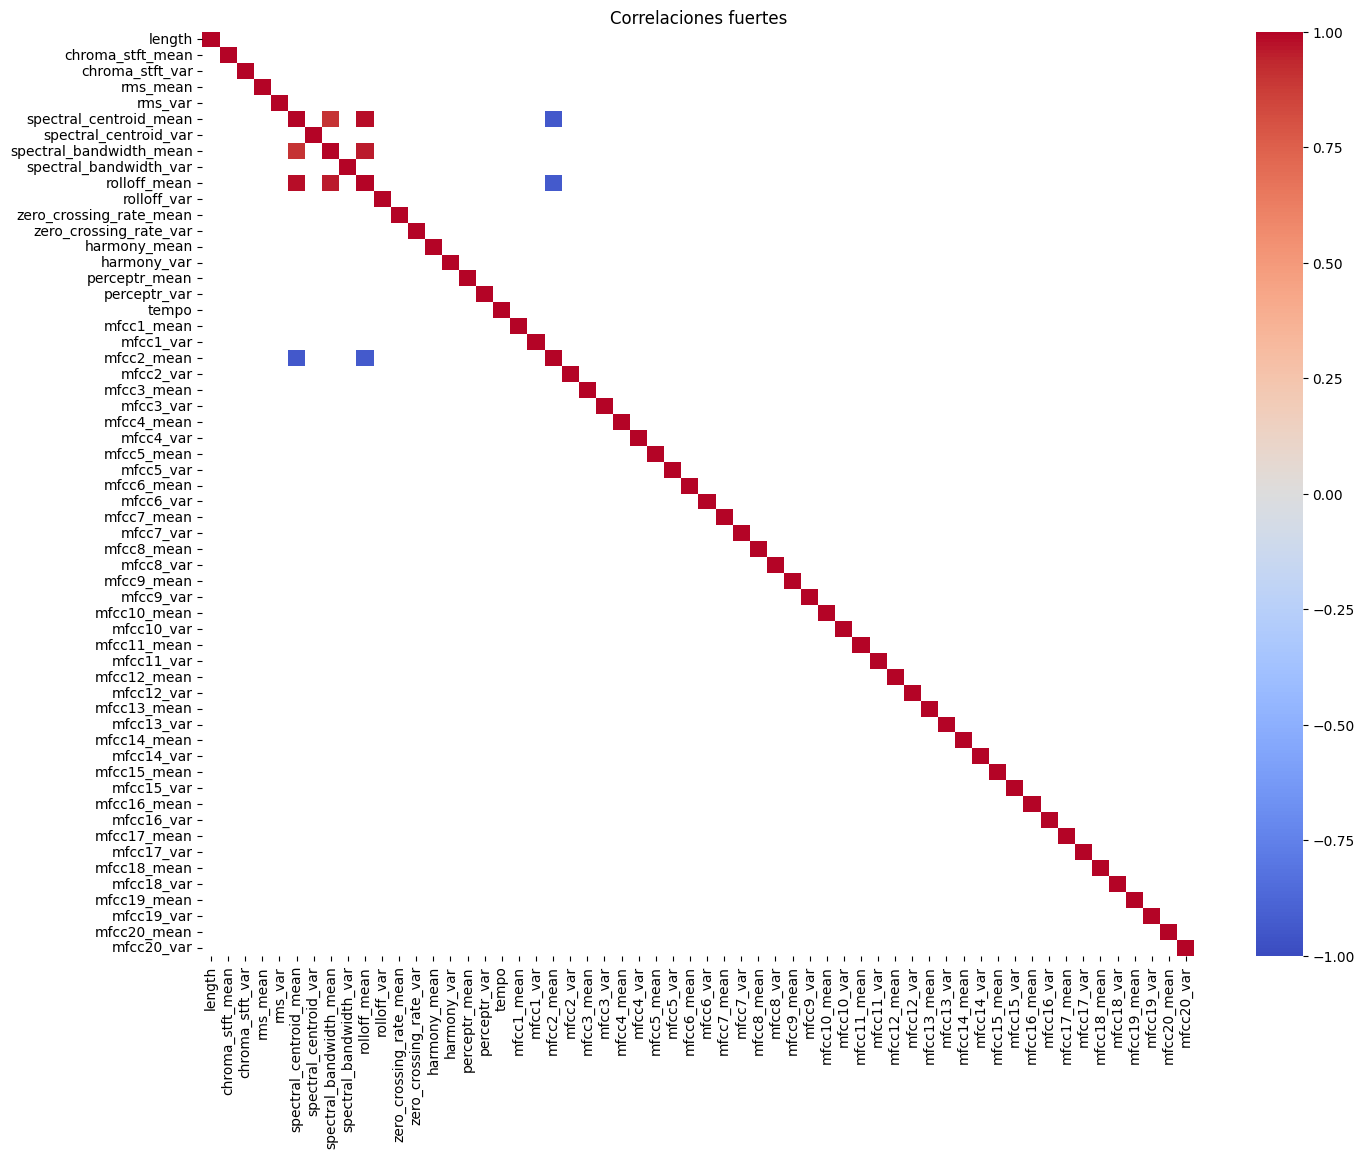

In [ ]:
#Vamos a filtrar por correlaciones fuertes
corr_filtrada = corr[(corr.abs() > 0.9)]

plt.figure(figsize=(16,12))

sns.heatmap(
    corr_filtrada,
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1
)

plt.title("Correlaciones fuertes")
plt.show()

In [ ]:
#Ver los pares más fuertes
pares_fuertes = (
    corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
        .stack()
        .sort_values(ascending=False)
)

pares_fuertes = pares_fuertes[pares_fuertes.abs() > 0.9]

display(pares_fuertes)

,,0
spectral_centroid_mean,rolloff_mean,0.979637
spectral_bandwidth_mean,rolloff_mean,0.956189
spectral_centroid_mean,spectral_bandwidth_mean,0.904435
rolloff_mean,mfcc2_mean,-0.934302
spectral_centroid_mean,mfcc2_mean,-0.940180


**Conclusión**: El análisis de correlación entre las variables predictoras ha permitido identificar varios pares de variables con una correlación muy elevada (|r| > 0,9), lo que indica la existencia de información redundante. En concreto, spectral_centroid_mean y rolloff_mean presentan una correlación de 0,98, mientras que spectral_bandwidth_mean también muestra una alta correlación con ambas variables (0,96 y 0,90, respectivamente). No obstante, estas características describen aspectos muy similares del contenido espectral de audio, por lo que es esperable que presenten una fuerte relación entre sí.

La presencia de esta redundancia puede afectar especialmente a modelos lineales, como la Regresión Logística o SVM, donde la multicolinealidad puede dificultar la interpretación de los coeficientes y reducir la estabilidad del modelo. Sin embargo, otros algoritmos de clasificación, como los árboles de decisión o los métodos basados en conjuntos de árboles (por ejemplo, Random Forest), son mucho menos sensibles a este problema.

Por este motivo, en una primera fase del estudio se mantendrán todas las variables para el entrenamiento de los distintos modelos de clasificación. Posteriormente, la comparación de su rendimiento permitirá determinar si la eliminación de alguna de las variables altamente correlacionadas o la aplicación de técnicas de selección de características contribuye a mejorar la capacidad predictiva del modelo sin pérdida significativa de información.

##Método de reducción de la dimensionalidad

No obligatorio, se podrá hacer alguna prueba para ver si alguno de los modelos lineales (si hacemos alguno de ellos) mejora su rendimiento con esta reducción de dimensionalidad